# Modelagem com o Prophet

Nesta aula vamos **criar e avaliar** um modelo de previsão com o Prophet.

Relembrando: o Prophet descreve a série como uma soma de componentes que dependem do tempo:

$$y(t) = g(t) + s(t) + h(t) + \varepsilon_t$$

- $g(t)$: tendência (com *changepoints*);
- $s(t)$: sazonalidades (anual, semanal, diária);
- $h(t)$: feriados e eventos;
- $\varepsilon_t$: erro.

**Prophet × ARIMA**: o ARIMA, outro modelo clássico, prevê o valor atual a partir dos **valores e erros passados** da própria série, e exige que a série seja estacionária. O Prophet trata a previsão como **ajuste de curvas** em função do tempo e não exige estacionariedade, porque modela a tendência explicitamente.

Importing plotly failed. Interactive plots will not work.


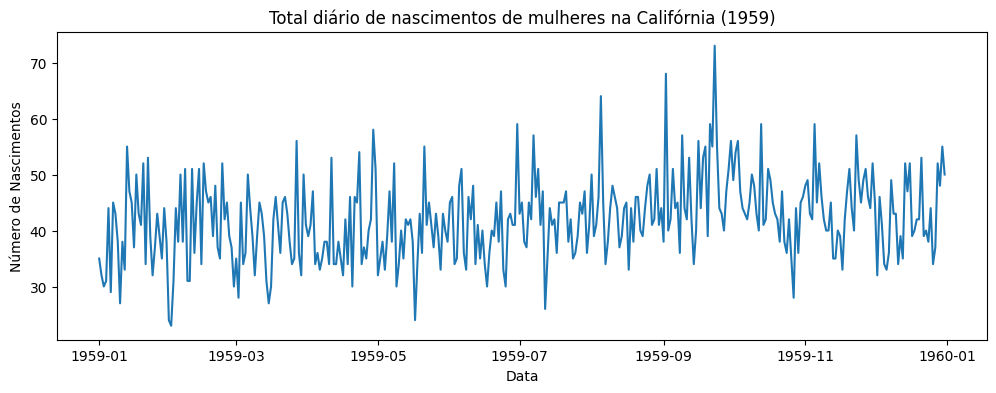

In [1]:
# No Google Colab o Prophet já vem instalado. Em outro ambiente, descomente a linha abaixo:
# !pip install prophet

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from prophet import Prophet
import logging
logging.getLogger('cmdstanpy').setLevel(logging.WARNING)  # reduz mensagens de log

# Load the dataset
data = pd.read_csv('https://raw.githubusercontent.com/jbrownlee/Datasets/refs/heads/master/daily-total-female-births.csv')
data['Date'] = pd.to_datetime(data['Date'])
data.set_index('Date', inplace=True)
# Plot the time series
plt.figure(figsize=(12, 4))
plt.plot(data['Births'])
plt.title('Total diário de nascimentos de mulheres na Califórnia (1959)')
plt.xlabel('Data')
plt.ylabel('Número de Nascimentos')
plt.show()

## Estacionariedade

Uma série é **estacionária** quando suas propriedades estatísticas — média, variância e autocorrelação — **não mudam ao longo do tempo**. Séries com tendência ou sazonalidade não são estacionárias.

O Prophet não exige estacionariedade, mas saber se a série é (ou não) estacionária ajuda a escolher a **tendência** do modelo: se a série oscila em torno de um nível constante, não faz sentido projetar uma tendência de crescimento.

Uma verificação visual simples usa as **médias e desvios móveis** que vimos na aula anterior:
- média móvel aproximadamente constante → sem tendência;
- desvio padrão móvel aproximadamente constante → variância estável.

(Existem também testes estatísticos formais, como o de Dickey-Fuller aumentado — ADF.)

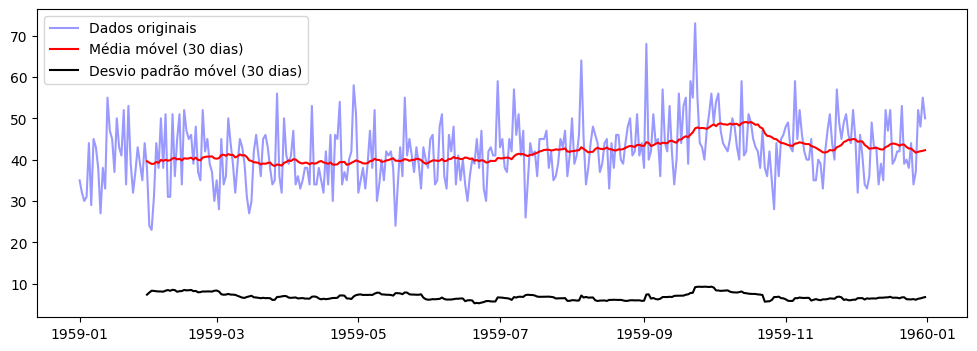

1º semestre: média = 39.8, desvio = 7.0
2º semestre: média = 44.2, desvio = 7.0


In [2]:
janela = 30  # dias

plt.figure(figsize=(12, 4))
plt.plot(data['Births'], color='blue', alpha=0.4, label='Dados originais')
plt.plot(data['Births'].rolling(janela).mean(), color='red', label=f'Média móvel ({janela} dias)')
plt.plot(data['Births'].rolling(janela).std(), color='black', label=f'Desvio padrão móvel ({janela} dias)')
plt.legend()
plt.show()

metade = len(data) // 2
print(f"1º semestre: média = {data['Births'][:metade].mean():.1f}, desvio = {data['Births'][:metade].std():.1f}")
print(f"2º semestre: média = {data['Births'][metade:].mean():.1f}, desvio = {data['Births'][metade:].std():.1f}")

**Interpretação**: o desvio padrão é praticamente o mesmo nos dois semestres (≈ 7) e não há sazonalidade visível. A média, porém, sobe de cerca de 40 para 44 nascimentos por dia, com um salto por volta de setembro. A série é **aproximadamente estacionária**, com uma mudança de nível no segundo semestre — guarde essa observação, ela será importante adiante.

## Autocorrelação

A *autocorrelation function* (ACF), ou função de autocorrelação, mede a correlação da série temporal consigo mesma em diferentes defasagens (*lags*).

- Lag 1 = correlação entre as observações no tempo $t$ e $t-1$
- Lag 2 = correlação entre as observações no tempo $t$ e $t-2$

Mostra até quando os valores do passado da série ajudam a prever os valores futuros.

A área azul do gráfico são os limites de confiança para testar se uma autocorrelação em determinado lag é estatisticamente significativa.

Como interpretar:

- **Lag significante**: se uma barra se estende além do limite de significância, indica autocorrelação significante naquele lag.
- **Declínio gradual**: um declínio gradual na altura das barras sugere uma dependência de longo prazo (tendência).
- **Padrões de sazonalidade**: picos regulares em alguns lags mostram sazonalidade nos dados.

### Autocorrelação Parcial

A autocorrelação parcial (PACF) mede a correlação entre observações em dois instantes, **descontando o efeito dos lags intermediários**. Isso isola a relação **direta** entre observações separadas por $k$ períodos.

- **Lag significante**: um pico significativo em um lag indica que aquele valor passado tem relação direta com o valor atual.
- **Ponto de corte**: o lag a partir do qual a PACF fica dentro do intervalo indica até onde vai essa dependência direta.

As funções abaixo calculam a ACF e a PACF (as mesmas da aula anterior).

In [3]:
def acf(x, nlags):
    """Autocorrelação r_k para k = 0..nlags."""
    x = np.asarray(x, dtype=float)
    x = x - x.mean()
    denominador = np.sum(x ** 2)
    return np.array([np.sum(x[k:] * x[:len(x) - k]) / denominador for k in range(nlags + 1)])


def pacf(x, nlags):
    """Autocorrelação parcial pelo algoritmo de Durbin-Levinson."""
    r = acf(x, nlags)
    phi = np.zeros((nlags + 1, nlags + 1))
    resultado = [1.0, r[1]]
    phi[1, 1] = r[1]
    for k in range(2, nlags + 1):
        num = r[k] - np.sum(phi[k - 1, 1:k] * r[k - 1:0:-1])
        den = 1 - np.sum(phi[k - 1, 1:k] * r[1:k])
        phi[k, k] = num / den
        for j in range(1, k):
            phi[k, j] = phi[k - 1, j] - phi[k, k] * phi[k - 1, k - j]
        resultado.append(phi[k, k])
    return np.array(resultado)


def plot_acf(x, lags, ax, parcial=False, titulo=None):
    """Correlograma com intervalo de confiança de 95% (área azul)."""
    n = len(x)
    valores = pacf(x, lags) if parcial else acf(x, lags)
    k = np.arange(lags + 1)
    if parcial:
        limite = np.full(lags + 1, 1.96 / np.sqrt(n))
    else:
        limite = 1.96 * np.sqrt((1 + 2 * np.concatenate([[0, 0], np.cumsum(valores[1:-1] ** 2)])) / n)
    limite[0] = np.nan
    ax.fill_between(k, -limite, limite, alpha=0.25, label='IC 95%')
    ax.vlines(k, 0, valores)
    ax.plot(k, valores, 'o', markersize=4)
    ax.axhline(0, color='black', linewidth=0.8)
    ax.set_ylim(-1.1, 1.1)
    ax.set_xlabel('Lag')
    ax.set_title(titulo or ('PACF' if parcial else 'ACF'))
    return valores

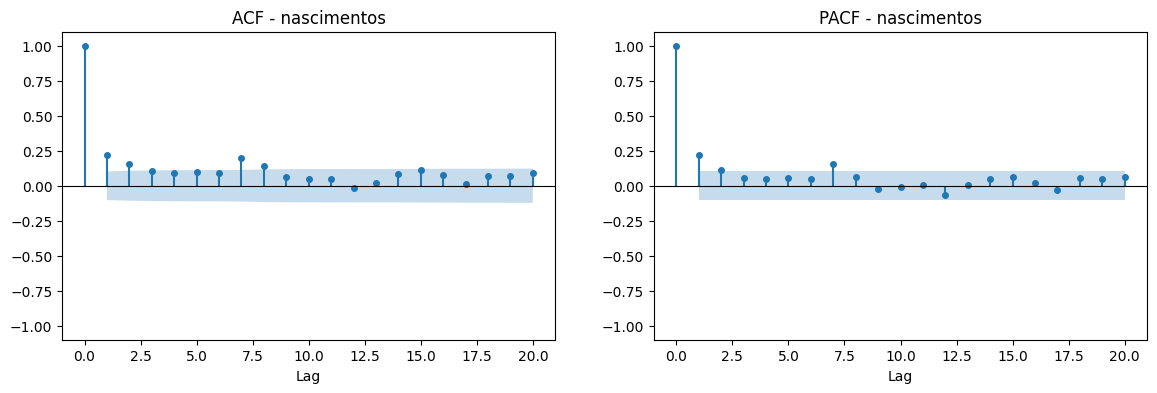

ACF  lags 1, 2, 7: [0.22 0.15 0.2 ]
PACF lags 1, 2, 7: [0.22 0.11 0.16]


In [4]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
plot_acf(data['Births'], lags=20, ax=axes[0], titulo='ACF - nascimentos')
plot_acf(data['Births'], lags=20, ax=axes[1], parcial=True, titulo='PACF - nascimentos')
plt.show()

print('ACF  lags 1, 2, 7:', np.round(acf(data['Births'], 7)[[1, 2, 7]], 2))
print('PACF lags 1, 2, 7:', np.round(pacf(data['Births'], 7)[[1, 2, 7]], 2))

**Interpretação**

- As autocorrelações são **fracas**: a maior é $r_1 \approx 0{,}22$. Saber quantos nascimentos houve ontem ajuda pouco a prever hoje.
- Os primeiros lags e o **lag 7** se destacam. O lag 7 sugere um leve **padrão semanal** (o mesmo dia da semana anterior), que vale a pena incluir no modelo.
- A ACF decai devagar nos primeiros lags e fica positiva por bastante tempo: reflexo da mudança de nível que vimos no gráfico de média móvel.
- Na PACF, quase tudo fica dentro do intervalo depois dos lags 1 e 7: há pouca dependência direta além disso.

## Parâmetros do Prophet

No ARIMA, a estrutura do modelo é definida pelos parâmetros $p$, $d$ e $q$. No Prophet, a estrutura é definida pelos **componentes** que ativamos e pela sua **flexibilidade**:

1. **Tendência** (`growth`)
   - `'linear'` (padrão): tendência linear por partes, que pode mudar de inclinação nos *changepoints*.
   - `'flat'`: sem tendência — o nível é constante. Útil para séries estacionárias.
   - `'logistic'`: crescimento com saturação (exige uma capacidade máxima `cap`).
2. **Flexibilidade da tendência** (`changepoint_prior_scale`, padrão 0.05)
   - Valores maiores deixam a tendência mudar mais (risco de *overfitting*); valores menores a deixam mais rígida.
3. **Sazonalidades** (`yearly_seasonality`, `weekly_seasonality`, `daily_seasonality`)
   - Ligam ou desligam cada padrão sazonal. Só faz sentido usar uma sazonalidade se houver dados suficientes para observá-la: com **um único ano** de dados não é possível estimar a sazonalidade anual.
4. **Modo da sazonalidade** (`seasonality_mode`): `'additive'` ou `'multiplicative'`.
5. **Feriados** (`holidays` ou `modelo.add_country_holidays(country_name='BR')`): efeitos de datas especiais.
6. **Intervalo de incerteza** (`interval_width`, padrão 0.8).

Para os nascimentos diários de 1959: usamos a **sazonalidade semanal** (sugerida pelo lag 7) e desligamos a anual (só há um ano) e a diária (há apenas um valor por dia).

## Treino e teste

Separamos os primeiros 80% dos dias para treino e os últimos 20% para teste. Em séries temporais a divisão respeita a ordem do tempo: treinamos com o passado e avaliamos no futuro.

Para medir o erro, usamos o **RMSE** (raiz do erro quadrático médio), na mesma unidade da série (nascimentos por dia):

$$\text{RMSE} = \sqrt{\frac{1}{n}\sum (y_t - \hat{y}_t)^2}$$

In [5]:
df_prophet = data.reset_index().rename(columns={'Date': 'ds', 'Births': 'y'})

# Split the data into train and test
train_size = int(len(df_prophet) * 0.8)
train, test = df_prophet[0:train_size], df_prophet[train_size:]
print(f'Treino: {train.ds.min():%d/%m} a {train.ds.max():%d/%m} ({len(train)} dias)')
print(f'Teste : {test.ds.min():%d/%m} a {test.ds.max():%d/%m} ({len(test)} dias)')


def rmse(real, previsto):
    return np.sqrt(np.mean((np.asarray(real) - np.asarray(previsto)) ** 2))


def plot_previsao(previsao, titulo):
    plt.figure(figsize=(14, 6))
    plt.plot(train.ds, train.y, label='Treino')
    plt.plot(test.ds, test.y, label='Real (teste)', color='orange')
    plt.plot(previsao.ds, previsao.yhat, label='Previsão', color='green')
    plt.fill_between(previsao.ds, previsao.yhat_lower, previsao.yhat_upper, color='k', alpha=.15)
    plt.title(titulo)
    plt.xlabel('Data')
    plt.ylabel('Número de Nascimentos')
    plt.legend()
    plt.show()

Treino: 01/01 a 19/10 (292 dias)
Teste : 20/10 a 31/12 (73 dias)


/usr/local/lib/python3.12/dist-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
02:12:33 - cmdstanpy - INFO - Chain [1] start processing


02:12:33 - cmdstanpy - INFO - Chain [1] done processing


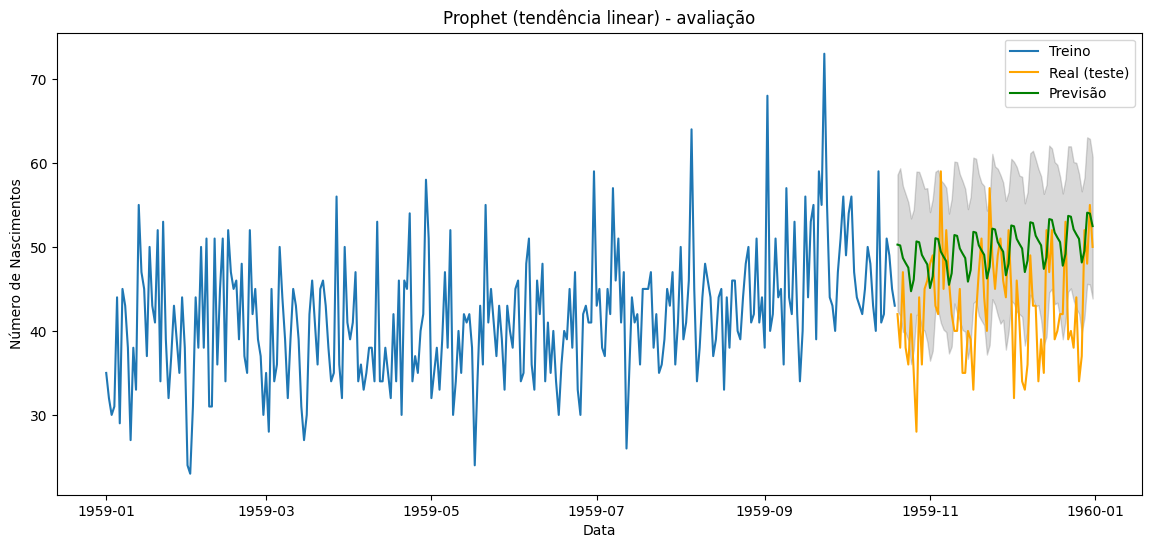

RMSE: 9.52


In [6]:
# Modelo com a tendência padrão (linear) e sazonalidade semanal
modelo = Prophet(yearly_seasonality=False, weekly_seasonality=True, daily_seasonality=False)
modelo.fit(train)

previsao = modelo.predict(test[['ds']])
rmse_linear = rmse(test.y, previsao.yhat)

plot_previsao(previsao, 'Prophet (tendência linear) - avaliação')
print(f'RMSE: {rmse_linear:.2f}')

## Comparando com um modelo de referência (*baseline*)

Um RMSE sozinho não diz se o modelo é bom. Precisamos compará-lo com um modelo **muito simples**. Aqui, o *baseline* é prever, para todos os dias do teste, a **média do período de treino**. Um modelo só vale a pena se for melhor que isso.

In [7]:
rmse_media = rmse(test.y, np.full(len(test), train.y.mean()))
print(f'RMSE baseline (média do treino): {rmse_media:.2f}')
print(f'RMSE Prophet (tendência linear): {rmse_linear:.2f}')

RMSE baseline (média do treino): 6.56
RMSE Prophet (tendência linear): 9.52


O Prophet com a configuração padrão ficou **pior** que a simples média! Os componentes ajudam a entender o motivo:

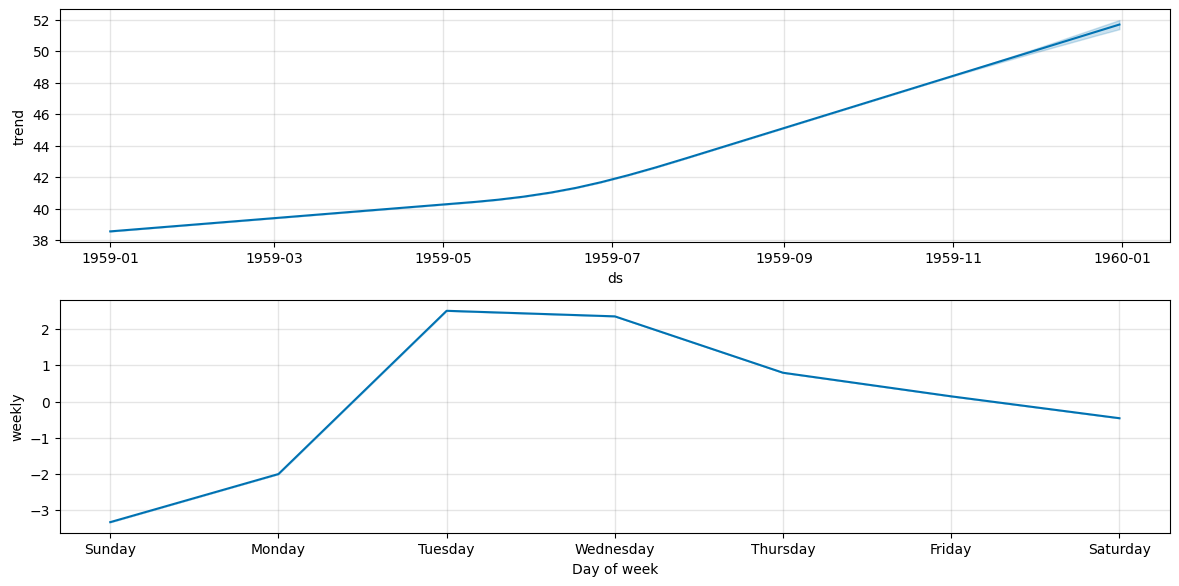

In [8]:
# Componentes ao longo de todo o período (treino + teste)
componentes = modelo.predict(df_prophet[['ds']])
fig = modelo.plot_components(componentes, figsize=(12, 6))
plt.show()

**Interpretação dos componentes**

- **trend**: o modelo interpretou a mudança de nível do segundo semestre como uma **tendência de crescimento** e a projetou para o período de teste. Mas a série não continua subindo: ela oscila em torno de um nível. É exatamente o risco que apontamos na análise de estacionariedade.
- **weekly**: há um efeito semanal pequeno — cerca de 3 nascimentos a menos aos domingos e 2 a menos às segundas, e 2 a 3 a mais às terças e quartas — coerente com o lag 7 da ACF.

Como a série é aproximadamente estacionária, faz mais sentido usar uma tendência **constante** (`growth='flat'`).

02:12:33 - cmdstanpy - INFO - Chain [1] start processing


02:12:33 - cmdstanpy - INFO - Chain [1] done processing


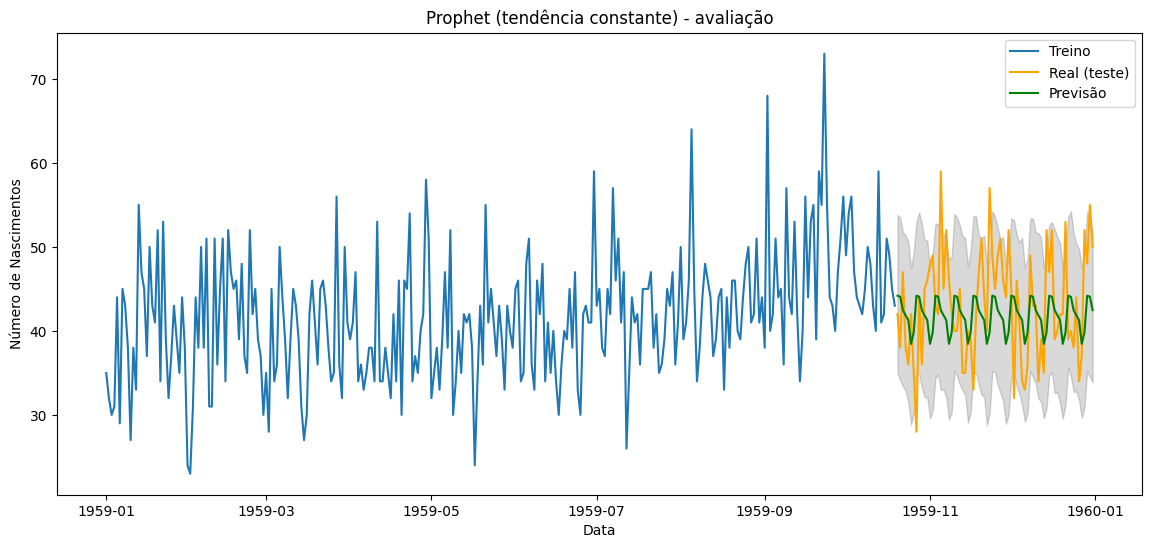

,Modelo,RMSE
0,Baseline (média do treino),6.56
1,Prophet - tendência linear,9.52
2,Prophet - tendência constante,6.81


In [9]:
modelo_flat = Prophet(growth='flat', yearly_seasonality=False, weekly_seasonality=True, daily_seasonality=False)
modelo_flat.fit(train)

previsao_flat = modelo_flat.predict(test[['ds']])
rmse_flat = rmse(test.y, previsao_flat.yhat)

plot_previsao(previsao_flat, 'Prophet (tendência constante) - avaliação')

pd.DataFrame({
    'Modelo': ['Baseline (média do treino)', 'Prophet - tendência linear', 'Prophet - tendência constante'],
    'RMSE': [rmse_media, rmse_linear, rmse_flat],
}).round(2)

## Conclusões

- Com `growth='flat'`, o erro cai bastante e fica **próximo do baseline**: o modelo passou a prever um nível constante com uma pequena variação semanal.
- Mesmo assim, não supera a média de forma clara. Isso não é um defeito do Prophet: como mostrou a ACF, essa série é **quase ruído** em torno de um nível. Quando não há tendência nem sazonalidade forte, não existe muito padrão a ser aprendido — nenhum modelo fará milagre.
- Lições para a modelagem:
  1. **Analise a série antes de modelar** (estacionariedade, ACF): isso guiou a escolha da tendência.
  2. **Sempre compare com um baseline simples.**
  3. **Escolha os componentes do modelo** de acordo com o que os dados mostram, em vez de confiar na configuração padrão.
- O Prophet mostra todo o seu potencial em séries com tendência e sazonalidade marcadas, como a de passageiros aéreos e a de produção de energia elétrica do exercício.